# Representation Retention

**Questions:** Does freezing hidden weights prevent deterioration? Does freezing
centering too remove the remaining error? Does an initial step size of 1e-7 help
when everything keeps learning?

The fixed teacher has 21 inputs, two two-LTU roots, and a two-LTU module that reads both roots plus the raw inputs. Four linear outputs read the first root and the composed module. The learner has eight LTUs in each of two layers, raw-input skip connections, and a readout of both layers. Use correct hidden
and output initialization, and 30 paired GPU seeds as the original correct-initialization experiment. Train for 1.5M
samples, scoring before each update. Noise std 1; achievable RMSE 1. No search or
shadows. Meta step size stays .01. Compare:

1. **Autostep baseline:** every weight and centering statistic learns; initial step 1e-5.
2. **Freeze hidden weights:** keep hidden weights and their optimizer states fixed;
   centering statistics and readout still learn; initial step 1e-5.
3. **Freeze hidden weights and centering:** also hold activation means and derivative
   traces fixed; only the readout learns; initial step 1e-5.
4. **Autostep 1e-7:** every weight and centering statistic learns; only the optimizer's
   initial step size changes. Initial weights, including spare units, match the baseline.

For each control, scale the embedded teacher to match its initial forward pass
(including whether the current observation updates centering). Verify the embedding
at full precision; keep training precision unchanged. Freeze controls are privileged
diagnostics. They do not show how to learn or track a changing representation.


In [1]:
from functools import partial
from pathlib import Path
from time import perf_counter
from typing import NamedTuple

import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'
RESULTS = Path('results')
RESULTS.mkdir(exist_ok=True)

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# Fixed historical diagnostic; keep its original settings.
N_INPUTS, N_OUTPUTS, MODULE_WIDTH = 21, 4, 2
WIDTH = 8
INIT_RATE, META_RATE, EMA_RATE = 1e-5, .01, 1e-3
NUM_STEPS, N_SEEDS, WINDOW = 1_500_000, 30, 1000
LABELS = ('Autostep 1e-5 (baseline)', 'Freeze hidden weights (diagnostic)',
          'Freeze hidden weights + centering (diagnostic)', 'Autostep 1e-7 (proposed)')

## Fixed teacher

In [3]:
class Stream(NamedTuple):
    w: jax.Array
    v: jax.Array
    rng: jax.Array


def init_stream(key):
    w_key, v_key, rng, _, _ = jax.random.split(key, 5)
    limits = jnp.concatenate((jnp.full(N_INPUTS, np.sqrt(3 / N_INPUTS)),
                             jnp.full(2 * MODULE_WIDTH, np.sqrt(3 / (2 * MODULE_WIDTH))),
                             jnp.asarray([.5])))
    # Keep the original random draws, discarding the unused third module.
    w = jax.random.uniform(w_key, (4, MODULE_WIDTH, len(limits)), minval=-1., maxval=1.) * limits
    w = w.at[:, :, -1].set(0.)[jnp.array([0, 1, 3])]
    v = jax.random.uniform(v_key, (N_OUTPUTS, 2 * MODULE_WIDTH + 1),
                           minval=-np.sqrt(3), maxval=np.sqrt(3)).at[:, -1].set(0.)
    return Stream(w, v, rng)


def target_mean(stream, x):
    roots_input = jnp.concatenate((x, jnp.zeros(2 * MODULE_WIDTH), jnp.ones(1)))
    a = (stream.w[0] @ roots_input > 0).astype(jnp.float32)
    b = (stream.w[1] @ roots_input > 0).astype(jnp.float32)
    composed_input = jnp.concatenate((x, 2 * a - 1, 2 * b - 1, jnp.ones(1)))
    d = (stream.w[2] @ composed_input > 0).astype(jnp.float32)
    return stream.v @ jnp.concatenate((2 * a - 1, 2 * d - 1, jnp.ones(1)))


def next_sample(stream):
    rng, x_key, noise_key = jax.random.split(stream.rng, 3)
    x = jax.random.rademacher(x_key, (N_INPUTS,), dtype=jnp.float32)
    y = target_mean(stream, x) + jax.random.normal(noise_key, (N_OUTPUTS,))
    return stream._replace(rng=rng), (x, y)

## Learner and retention controls

In [4]:
OPTIMIZER = optax_idbd(meta_lr=META_RATE, init_lr=INIT_RATE, autostep=True,
                       tau=1e4, version='squared_inputs')


class Learner(NamedTuple):
    w: tuple
    opt: object
    mean: tuple
    slope: tuple


def init_learner(key):
    weights = []
    for layer, subkey in enumerate(jax.random.split(key, 2)):
        fan_in = N_INPUTS + layer * WIDTH
        w = jax.random.uniform(subkey, (WIDTH, fan_in + 1), minval=-1., maxval=1.) * INIT_RATE
        weights.append(w.at[:, -1].set(0.))
    weights.append(jnp.zeros((N_OUTPUTS, 2 * WIDTH + 1)))
    weights = tuple(weights)
    return Learner(weights, OPTIMIZER.init(weights),
                   tuple(jnp.full(WIDTH, .5) for _ in range(2)),
                   tuple(jnp.zeros_like(w).at[:, -1].set(.25) for w in weights[:-1]))

def forward(weights, x, learner, freeze_center):
    sources, means, slopes, hidden = [], [], [], []
    inputs = x
    rate = jnp.where(freeze_center, 0., EMA_RATE)
    for w, mean, slope in zip(weights[:-1], learner.mean, learner.slope):
        sources.append(jnp.append(inputs, 1.)[None])
        z = w @ sources[-1][0]
        h = ltu(z)
        mean = mean + rate * (jax.lax.stop_gradient(h) - mean)
        sigmoid = jax.nn.sigmoid(z)
        derivative = jax.lax.stop_gradient(sigmoid * (1 - sigmoid))
        slope = slope + rate * (derivative[:, None] * jax.lax.stop_gradient(sources[-1]) - slope)
        correction = jnp.sum(slope * w, axis=1)
        h = h - mean + (jax.lax.stop_gradient(correction) - correction)
        hidden.append(h)
        means.append(mean)
        slopes.append(slope)
        inputs = jnp.concatenate((inputs, h))
    source = jnp.append(jnp.concatenate(hidden), 1.)
    sources.append(source[None])
    return weights[-1] @ source, (tuple(sources), tuple(means), tuple(slopes))


def embed_teacher(learner, teacher, freeze_center):
    n, m = N_INPUTS, MODULE_WIDTH
    width = learner.w[0].shape[0]
    first, second, out = learner.w
    first = first.at[:2*m, :n].set(teacher.w[:2, :, :n].reshape(2*m, n))
    first = first.at[:2*m, -1].set(teacher.w[:2, :, -1].reshape(-1))
    # Moving means include the current observation; compensate for that scaling
    # at initialization. Fixed means use h - .5 without the EMA scaling.
    scale = jnp.where(freeze_center, 1., 1. - EMA_RATE)
    second = second.at[:m].set(0.)
    second = second.at[:m, :n].set(teacher.w[-1, :, :n])
    second = second.at[:m, n:n+2*m].set(2 * teacher.w[-1, :, n:n+2*m] / scale)
    second = second.at[:m, -1].set(teacher.w[-1, :, -1])
    out = jnp.zeros_like(out).at[:, :m].set(2 * teacher.v[:, :m] / scale)
    out = out.at[:, width:width+m].set(2 * teacher.v[:, m:2*m] / scale)
    out = out.at[:, -1].set(teacher.v[:, -1])
    return learner._replace(w=(first, second, out))


def step(learner, x, y, mode):
    def loss(w):
        prediction, aux = forward(w, x, learner, mode == 2)
        return .5 * jnp.sum((prediction - y) ** 2), aux

    (loss, (sources, means, slopes)), grads = jax.value_and_grad(loss, has_aux=True)(learner.w)
    updates, opt = OPTIMIZER.update((grads, None, sources), learner.opt, learner.w)
    w = jax.tree.map(jnp.add, learner.w, updates)
    freeze = (mode == 1) | (mode == 2)

    def keep_hidden(new, old):
        return tuple(jnp.where(freeze, b, a) for a, b in zip(new[:-1], old[:-1])) + (new[-1],)

    w = keep_hidden(w, learner.w)
    opt = opt._replace(**{name: keep_hidden(getattr(opt, name), getattr(learner.opt, name))
                         for name in ('beta', 'h', 'v')})
    return learner._replace(w=w, opt=opt, mean=means, slope=slopes), 2 * loss / len(y)

## Training

In [5]:
@partial(jax.jit, static_argnames=('n_seeds',))
def initialize(n_seeds=N_SEEDS):
    keys = jax.vmap(lambda seed: jax.random.split(jax.random.PRNGKey(seed)))(jnp.arange(n_seeds, dtype=jnp.int32))
    stream = jax.vmap(init_stream)(keys[:, 0])
    learner = jax.vmap(init_learner)(keys[:, 1])

    def variant(mode):
        state = jax.vmap(embed_teacher, in_axes=(0, 0, None))(learner, stream, mode == 2)
        beta = jnp.log(jnp.where(mode == 3, 1e-7, INIT_RATE))
        opt = state.opt._replace(init_beta=jnp.full_like(state.opt.init_beta, beta),
                                beta=jax.tree.map(lambda a: jnp.full_like(a, beta), state.opt.beta))
        return state._replace(opt=opt)

    return jax.vmap(variant)(jnp.arange(len(LABELS))), stream


@partial(jax.jit, static_argnames=('n_windows',))
def train(initial, n_windows):
    sample_batch = jax.vmap(next_sample)
    update_batch = jax.vmap(jax.vmap(step, in_axes=(0, 0, 0, None)), in_axes=(0, None, None, 0))

    def sample(carry, _):
        learners, stream = carry
        stream, (x, y) = sample_batch(stream)
        learners, mse = update_batch(learners, x, y, jnp.arange(len(LABELS)))
        return (learners, stream), mse

    def window(carry, _):
        carry, mse = jax.lax.scan(sample, carry, length=WINDOW)
        return carry, mse.mean(axis=0)

    final, mse = jax.lax.scan(window, initial, length=n_windows)
    return final, mse.transpose(1, 2, 0)

In [6]:
@jax.jit
def initial_prediction_errors(initial):
    learners, stream = initial
    x = jax.random.rademacher(jax.random.PRNGKey(2026), (256, N_INPUTS), dtype=jnp.float32)
    means = jax.vmap(lambda s: jax.vmap(lambda a: target_mean(s, a))(x),
                     in_axes=(0,))(stream)
    def one_variant(states, mode):
        return jax.vmap(lambda state: jax.vmap(
            lambda a: forward(state.w, a, state, mode == 2)[0])(x))(states)
    predictions = jax.vmap(one_variant)(learners, jnp.arange(len(LABELS)))
    error = predictions - means[None]
    return jnp.max(jnp.abs(error), axis=(1, 2, 3)), jnp.mean(error ** 2, axis=(1, 2, 3))


started = perf_counter()
initial = initialize(N_SEEDS)
initial_expected_rmse = np.sqrt(1. + np.asarray(initial_prediction_errors(initial)[1]))
with jax.default_matmul_precision('highest'):
    initial_errors = np.asarray(initial_prediction_errors(initial)[0])
assert np.all(initial_errors < 1e-5), initial_errors
assert np.all(initial_expected_rmse < 1.01), initial_expected_rmse
for w in initial[0].w:
    np.testing.assert_array_equal(w[0], w[3])
np.testing.assert_allclose(initial[0].opt.beta[0][3], np.log(1e-7), atol=1e-6)
print('Maximum initial embedding errors (full precision):', initial_errors)
print('Initial expected noisy RMSE (training precision):', initial_expected_rmse)
print('1e-7 changes only optimizer initialization.')

Maximum initial embedding errors (full precision): [9.536743e-07 9.536743e-07 0.000000e+00 9.536743e-07]
Initial expected noisy RMSE (training precision): [1.0008779 1.0008779 1.        1.0008779]
1e-7 changes only optimizer initialization.


In [7]:
final, mse = train(initial, NUM_STEPS // WINDOW)
result = {'mse': np.asarray(mse), 'seconds': perf_counter() - started,
          'labels': np.array(LABELS), 'initial_errors': initial_errors,
          'initial_expected_rmse': initial_expected_rmse}
assert np.isfinite(result['mse']).all()
# Check actual end states, not just the control flags.
for before, after in zip(initial[0].w[:-1], final[0].w[:-1]):
    np.testing.assert_array_equal(before[1:3], after[1:3])
    assert np.all(np.asarray(jnp.any(before[jnp.array([0, 3])] != after[jnp.array([0, 3])], axis=(-2, -1))))
for name in ('mean', 'slope'):
    for before, after in zip(getattr(initial[0], name), getattr(final[0], name)):
        np.testing.assert_array_equal(before[2], after[2])
        assert np.any(np.asarray(before[1] != after[1]))
for name in ('beta', 'h', 'v'):
    for before, after in zip(getattr(initial[0].opt, name)[:-1], getattr(final[0].opt, name)[:-1]):
        np.testing.assert_array_equal(before[1:3], after[1:3])
assert np.all(np.asarray(jnp.any(initial[0].w[-1] != final[0].w[-1], axis=(-2, -1))))
np.savez_compressed(RESULTS / 'retention_controls.npz', **result)

## Plots

Autostep $10^{-5}$: first 1k 1.01552; previous 150k 1.04775; final 150k 1.04984; late change +0.00209 ± 0.00131 (paired 2 SE)
Frozen Hidden: first 1k 1.01367; previous 150k 1.01831; final 150k 1.01826; late change -0.00004 ± 0.00076 (paired 2 SE)
Frozen Hidden + Centering: first 1k 1.00210; previous 150k 1.00003; final 150k 1.00002; late change -0.00001 ± 0.00056 (paired 2 SE)
Autostep $10^{-7}$: first 1k 1.01367; previous 150k 1.02405; final 150k 1.02539; late change +0.00134 ± 0.00101 (paired 2 SE)
Complete comparison: 45.4s including checks and compilation.


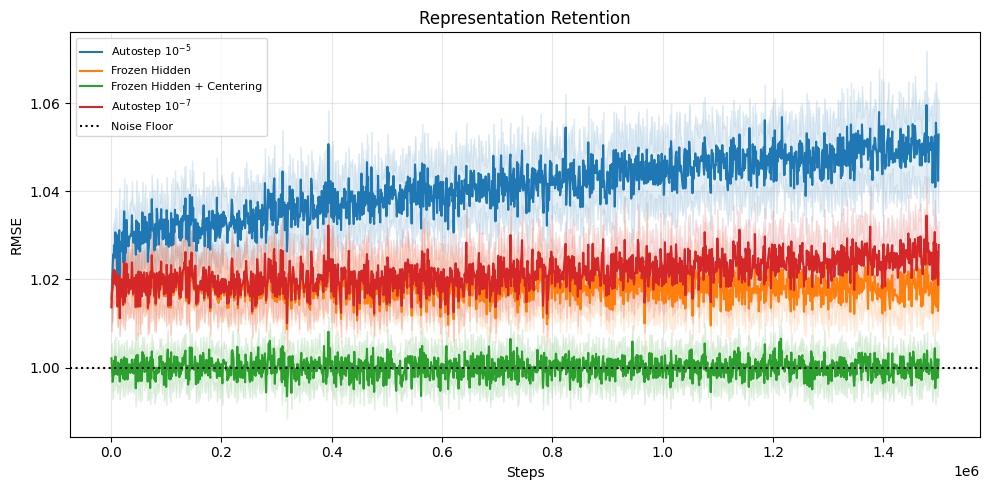

In [8]:
fig, ax = plt.subplots(figsize=(10, 5))
steps = np.arange(1, result['mse'].shape[-1] + 1) * WINDOW
labels = (r'Autostep $10^{-5}$', 'Frozen Hidden', 'Frozen Hidden + Centering', r'Autostep $10^{-7}$')
for label, values in zip(labels, result['mse']):
    rmse = np.sqrt(values)
    mean = rmse.mean(axis=0)
    band = 2 * rmse.std(axis=0, ddof=1) / np.sqrt(N_SEEDS)
    line, = ax.plot(steps, mean, label=label)
    ax.fill_between(steps, mean - band, mean + band, color=line.get_color(), alpha=.12)
    early = np.sqrt(values[:, :1].mean(axis=1))
    previous = np.sqrt(values[:, -300:-150].mean(axis=1))
    late = np.sqrt(values[:, -150:].mean(axis=1))
    delta = late - previous
    print(f'{label}: first 1k {early.mean():.5f}; previous 150k {previous.mean():.5f}; '
          f'final 150k {late.mean():.5f}; late change {delta.mean():+.5f} '
          f'± {2 * delta.std(ddof=1) / np.sqrt(N_SEEDS):.5f} (paired 2 SE)')
ax.axhline(1., color='black', ls=':', label='Noise Floor')
ax.set(xlabel='Steps', ylabel='RMSE',
       title='Representation Retention')
ax.grid(True, alpha=.3)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
print(f'Complete comparison: {result["seconds"]:.1f}s including checks and compilation.')

**Result: 45.4s including checks and compilation; 30 paired seeds, 1.5M samples.**

| Condition | Final-150k RMSE | Preceding-150k RMSE |
|---|---:|---:|
| Autostep 1e-5 baseline | 1.04984 | 1.04775 |
| Freeze hidden weights | 1.01826 | 1.01831 |
| Freeze hidden weights and centering | **1.00002** | 1.00003 |
| Autostep 1e-7 | 1.02539 | 1.02405 |

The baseline curve is bit-identical to the original correct-initialization experiment. End-state checks confirm the
specified weights, optimizer states, and centering statistics stayed frozen;
readouts changed in every condition. Initial embeddings match the teacher within
1e-6 at full precision.

**Interpretation:** moving centering statistics impose a persistent prediction cost
even with correct, fixed hidden weights. With hidden weights and centering both fixed,
readout learning preserves performance at the noise floor. Allowing hidden-weight
updates causes additional deterioration in this setting. These effects interact;
the RMSE differences should not be treated as an additive decomposition.

A 1e-7 initial step size helps but does not stop deterioration: late RMSE increases
by 0.00134 ± 0.00101 (paired 2 SE), versus 0.00209 ± 0.00131 for the baseline.
This tests retaining a supplied solution, not discovering one from random initialization.

**Next:** test compensating downstream bias weights when centering means change.
Subtracting a changed mean shifts downstream LTU thresholds unless the corresponding
bias weights compensate. That would let centering adapt while preserving the current
computation; it still would not establish that hidden-weight updates are stable.
